In [ ]:
import pandas as pd

In [ ]:
import numpy as num

In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
df = pd.read_csv("/content/auto-mpg (3).csv")

In [ ]:
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79,2625,18.6,82,1,ford ranger


In [ ]:
df.tail()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
393,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79,2625,18.6,82,1,ford ranger
397,31.0,4,119.0,82,2720,19.4,82,1,chevy s-10


In [ ]:
df.tail()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
393,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79,2625,18.6,82,1,ford ranger
397,31.0,4,119.0,82,2720,19.4,82,1,chevy s-10


In [ ]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [ ]:
df.describe()

,mpg,cylinders,displacement,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


In [ ]:
df.dtypes

,0
mpg,float64
cylinders,int64
displacement,float64
horsepower,object
weight,int64
acceleration,float64
model year,int64
origin,int64
car name,object


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB


In [ ]:
df.shape

(398, 9)

In [ ]:
numeric_columns = df.select_dtypes(include=['int64','float64']).columns.tolist()
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()

In [ ]:
print("\n Numberic Columns:")
print(numeric_columns)


 Numberic Columns:
['mpg', 'cylinders', 'displacement', 'weight', 'acceleration', 'model year', 'origin']


In [ ]:
print("\n Categorical Columns:")
print(categorical_columns)


 Categorical Columns:
['horsepower', 'car name']


In [ ]:
print("\n Missing values before Cleaning:")
print(df.isnull().sum())


 Missing values before Cleaning:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64


In [ ]:
df['horsepower'] = pd.to_numeric(df['horsepower'],errors='coerce')

In [ ]:
df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce')
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())

In [ ]:

X_numeric = df.select_dtypes(include=['int64', 'float64'])
print("Selected Numeric Columns for Scaling:")
print(X_numeric.columns.tolist())

Selected Numeric Columns for Scaling:
['mpg', 'cylinders', 'displacement', 'weight', 'acceleration', 'model year', 'origin']


In [ ]:

scaler = MinMaxScaler()
scaled_features = scaler.fit_transform(X_numeric)


df_scaled = pd.DataFrame(scaled_features, columns=X_numeric.columns)

display(df_scaled.head())

,mpg,cylinders,displacement,weight,acceleration,model year,origin
0,0.239362,1.0,0.617571,0.536150,0.238095,0.0,0.0
1,0.159574,1.0,0.728682,0.589736,0.208333,0.0,0.0
2,0.239362,1.0,0.645995,0.516870,0.178571,0.0,0.0
3,0.186170,1.0,0.609819,0.516019,0.238095,0.0,0.0
4,0.212766,1.0,0.604651,0.520556,0.148810,0.0,0.0


In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
encoder = LabelEncoder()

In [ ]:
df['car name'] = encoder.fit_transform(df['car name'])
print(df['car name'].head())

0     49
1     36
2    231
3     14
4    161
Name: car name, dtype: int64


In [ ]:
import matplotlib.pyplot as plt


In [ ]:
from sklearn.decomposition import PCA

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
X = df[['mpg','cylinders','displacement','horsepower','weight','acceleration','model year']]

In [ ]:
X = X.fillna(X.mean())

In [ ]:
X_scaled = StandardScaler().fit_transform(X)

In [ ]:
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

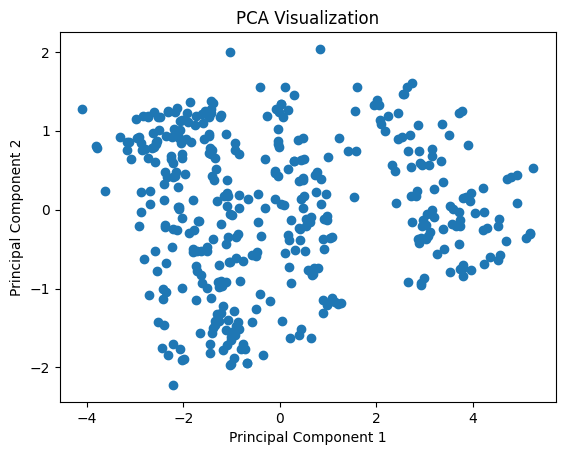

In [ ]:
plt.scatter(principal_components[:, 0], principal_components[:, 1])
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Visualization')
plt.show()
